- **Part 2 · Case study** has the five steps of Part IV. Each step has the same number as the tag *Notebook · Step N* on its slide.


The data are the *Amazon Unlocked Mobile* reviews of Weeks 5 and 6, with the same split into 23,052 training and 7,684 test reviews.


## Setup

In [1]:
!pip install -q gensim google-genai

In [2]:
import re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

### Load the data

Choose how to load the file `Amazon_Unlocked_Mobile.csv`:

- `"kaggle"`: the notebook downloads it from Kaggle with `kagglehub` (about 33 MB).
- `"upload"`: you upload the file from your computer (about 130 MB).

In [3]:
SOURCE = "kaggle"   # or "upload"

if SOURCE == "kaggle":
    import kagglehub, glob
    path = kagglehub.dataset_download("nehasontakke/amazon-unlocked-mobilecsv")
    CSV = glob.glob(path + "/**/*.csv", recursive=True)[0]
else:
    from google.colab import files
    uploaded = files.upload()
    CSV = next(iter(uploaded))

df = pd.read_csv(CSV)
df.shape

Using Colab cache for faster access to the 'amazon-unlocked-mobilecsv' dataset.


(413840, 6)

### The same split as in Weeks 5 and 6

A 10% sample of the reviews, without missing values and without the 3-star reviews. A review is positive when it has 4 or 5 stars.

In [4]:
sample = df.sample(frac=0.1, random_state=10).dropna()
sample = sample[sample['Rating'] != 3]
sample['Positively Rated'] = np.where(sample['Rating'] > 3, 1, 0)

X_train, X_test, y_train, y_test = train_test_split(sample['Reviews'], sample['Positively Rated'], random_state=0)
len(X_train), len(X_test)

(23052, 7684)

# Part 2 · Case study

## Step 1 · Train word2vec on unlabelled reviews

The corpus is **the 23,052 training reviews**, the same as in Weeks 5 and 6. Their labels are not used, and the test reviews stay unseen until the evaluation.

| Parameter | What it sets |
|---|---|
| `vector_size=100` | d: every word gets a vector of 100 numbers |
| `window=5` | up to 5 context words on each side of the centre word |
| `min_count=5` | words seen fewer than 5 times get no vector |
| `sg=1` | the skip-gram task; `sg=0`, the default, trains CBOW |
| `negative=5` | each example compares the real word with 5 random words, not all the vocabulary |
| `seed=42`, `workers=1` | the same vectors in every run; `epochs=5` makes 5 passes over the corpus |

In [5]:
from gensim.models import Word2Vec

tok = re.compile(r'(?u)\b\w\w+\b')          # the same tokenizer as CountVectorizer (defined here too, so Part 2 runs without Part 1)

# the 23,052 training reviews; their labels are not used
sents = [tok.findall(t.lower()) for t in X_train]

w2v = Word2Vec(sents, vector_size=100, window=5, min_count=5,
               sg=1, epochs=5, seed=42, workers=1)
len(sents), len(w2v.wv)

(23052, 5667)

Each word is now a row of the embedding matrix E, which gensim keeps in `w2v.wv`:

In [6]:
print(w2v.wv.vectors.shape)       # E: one row per word, d = 100 columns
w2v.wv['battery'][:10]            # the first 10 of the 100 numbers of battery

(5667, 100)


array([ 0.2446574 ,  0.48255077, -0.59075075,  0.5380171 ,  0.22649343,
       -0.37780076, -0.03809978,  0.11803368,  0.27241284,  0.13600005],
      dtype=float32)

## Step 2 · Nearest neighbours

In [7]:
w2v.wv.most_similar('dies', topn=5)

[('die', 0.855934202671051),
 ('draining', 0.8505602478981018),
 ('drain', 0.8459076285362244),
 ('recharge', 0.8380938768386841),
 ('standby', 0.8333593606948853)]

In [ ]:
for a, b in [('good', 'great'), ('good', 'bad'), ('love', 'hate')]:
    print(f'{a} – {b}: {w2v.wv.similarity(a, b):.2f}')

**In class.** Pick two words of your own. Find one list of neighbours that makes sense and one that does not, and explain the second one with the distributional hypothesis.

In [ ]:
w2v.wv.most_similar('refund', topn=5)     # change the word

*Optional.* Word arithmetic: which word is to *apple* what *galaxy* is to *samsung*? And to *better* what *bad* is to *good*? The three input words are left out of the answer.

In [ ]:
print(w2v.wv.most_similar(positive=['galaxy', 'apple'], negative=['samsung'], topn=3))
print(w2v.wv.most_similar(positive=['bad', 'better'], negative=['good'], topn=3))

### Step 2b · A pretrained model: GloVe

GloVe (Stanford, 2014) is the second method of the slide *Three ways to learn word embeddings*. We do not train it: we download vectors that Stanford learned from **Wikipedia and news** (6 billion words, 400,000 words in the vocabulary, 50 numbers per word, about 66 MB). Then we compare the neighbours of the same words in the two models.

In [8]:
import gensim.downloader as api
glove = api.load('glove-wiki-gigaword-50')
print(len(glove), 'words with', glove.vector_size, 'numbers each')

[==================================================] 100.0% 66.0/66.0MB downloaded
400000 words with 50 numbers each


In [ ]:
for word in ['dies', 'excellent', 'refund', 'screen']:
    print(word)
    print('   GloVe, Wikipedia and news :', [w for w, s in glove.most_similar(word, topn=5)])
    print('   our word2vec, reviews     :', [w for w, s in w2v.wv.most_similar(word, topn=5)])
print('good – bad   GloVe:', round(float(glove.similarity('good', 'bad')), 2),
      '  our word2vec:', round(float(w2v.wv.similarity('good', 'bad')), 2))

**Questions.**
1. Why are the neighbours of *dies* so different in the two models? Which meaning of the word does each corpus see?
2. Is *good* close to *bad* in GloVe too? What does this tell you about opposites?
3. Which model would you use for our reviews, and which for news articles? Recall the slide *Creating word embeddings: the corpus*.

A word that the model never saw, or saw fewer than 5 times, has no vector:

In [ ]:
try:
    w2v.wv['excellenttt']
except KeyError as e:
    print('KeyError:', e)

## Step 3 · A map of our space

The vectors have 100 numbers, so we cannot draw them. **PCA** finds the two directions in which the vectors of the chosen words vary most and places each word along them.

Share of the spread kept by the two axes: 0.54


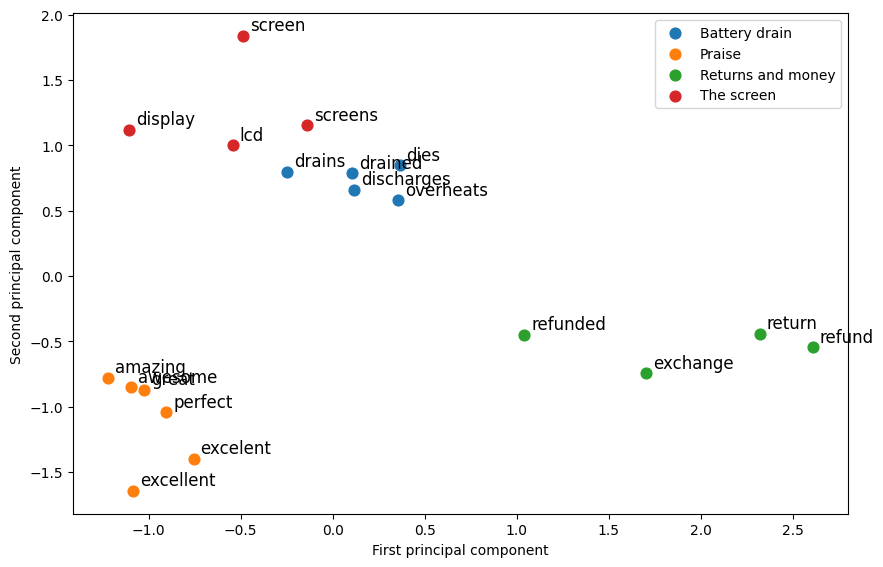

In [9]:
groups = {'Battery drain': ['dies', 'drains', 'drained', 'discharges', 'overheats'],
          'Praise': ['great', 'excellent', 'excelent', 'awesome', 'amazing', 'perfect'],
          'Returns and money': ['refund', 'return', 'refunded', 'exchange'],
          'The screen': ['screen', 'display', 'lcd', 'screens']}
words = [w for ws in groups.values() for w in ws]

pca = PCA(n_components=2)
xy = pca.fit_transform(w2v.wv[words])
print('Share of the spread kept by the two axes:', pca.explained_variance_ratio_.sum().round(2))

plt.figure(figsize=(10, 6.5))
i = 0
for name, ws in groups.items():
    pts = xy[i:i + len(ws)]; i += len(ws)
    plt.scatter(pts[:, 0], pts[:, 1], s=60, label=name)
    for w, (x, y) in zip(ws, pts):
        plt.annotate(w, (x, y), xytext=(5, 4), textcoords='offset points', fontsize=12)
plt.xlabel('First principal component'); plt.ylabel('Second principal component')
plt.legend(); plt.show()

The two axes keep only part of the spread of the 100 numbers, so two words that look close on the picture may not be close in 100 dimensions. The cosine in all 100 dimensions stays the measure.

**Try it.** Add the word `'bad'` to the group *Praise* and run the cell again. Where does it land, and why?

**Practise it.** Step 1 of the interactive exercise opens our model in the Embedding Projector, with all its 5,667 words.